# 30 · Compare frozen encoders and assemble the manuscript table

Use frozen ResNet-50 V1 and EfficientNet-B0 V1 with the same full-frame 56 × 56 preprocessing. Compare final pooled cosine, local mean and local second-order pooling. Then compile one table per panel with the search policy visible.

Relative to the local mean from the same feature grid, local Q improves fresh same-digit top-1 by 5.36 points in each backbone. The full comparison table keeps the alignment policy and both gallery protocols visible.

In [1]:
from pathlib import Path
import sys,json
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'observables').is_dir())
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.stage8 import BASELINES,FROZEN,PRIMARY,VIEWS,contrast
OUT=ROOT/'results'/'stage8'
plt.rcParams.update({'figure.dpi':110,'figure.constrained_layout.use':True,
                     'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()
summary=pd.read_csv(OUT/'summary.csv')
decisions=pd.read_csv(OUT/'decisions.csv.gz')

## Representation and observable
The final embedding uses normalized global average pooling. The local comparison uses the stride-eight intermediate feature map for each architecture. Normalize each nonzero local vector. Compare the normalized first moment and the normalized traceless second moment with cosine. This holds the intermediate feature extraction fixed within each backbone. It does not give a controlled comparison of architecture alone because widths, weights and pretraining procedures differ.

In [3]:
info=json.loads((OUT/'frozen_manifest.json').read_text())
display(pd.DataFrame(info['models']).T)
rows=[]
for panel in ['pilot','replication']:
    f=decisions[(decisions.panel==panel)&(decisions.gallery_type=='full')]
    for backbone in ['ResNet-50','EfficientNet-B0']:
        for ep in ['identity','class']:
            rows.append((panel,backbone,ep,*contrast(f,backbone+' local Q',backbone+' local mean',ep)))
contrasts=pd.DataFrame(rows,columns=['panel','backbone','endpoint','Q minus mean','low95','high95'])
display(contrasts.round(4));contrasts.to_csv(OUT/'frozen_pooling_contrasts.csv',index=False)

,weights,sha256,seconds
ResNet-50,https://download.pytorch.org/models/resnet50-0...,0676ba61b6795bbe1773cffd859882e5e297624d384b69...,191.920945
EfficientNet-B0,https://download.pytorch.org/models/efficientn...,7f5810bc96def8f7552d5b7e68d53c4786f81167d28291...,77.394767


,panel,backbone,endpoint,Q minus mean,low95,high95
0,pilot,ResNet-50,identity,0.0332,0.0258,0.0410
1,pilot,ResNet-50,class,0.0418,0.0336,0.0496
2,pilot,EfficientNet-B0,identity,0.0781,0.0656,0.0914
3,pilot,EfficientNet-B0,class,0.0379,0.0230,0.0535
4,replication,ResNet-50,identity,0.0302,0.0221,0.0383
5,replication,ResNet-50,class,0.0536,0.0443,0.0635
6,replication,EfficientNet-B0,identity,0.0750,0.0654,0.0846
7,replication,EfficientNet-B0,class,0.0536,0.0432,0.0648


## Comparison table
The pilot and replication columns describe different candidate pools. The replication source-excluded task has three eligible matches. Accuracy is averaged across the same eight perturbations within each panel. Bold marks column maxima among the displayed rows. The full result CSV retains all tested methods.

,Search,Pilot source,Pilot digit,Fresh source,Fresh digit
Fixed pixels,fixed,75.90,30.31,72.01,45.65
Aligned pixels,±3 px,95.94,37.50,93.91,52.27
Aligned ZNCC,±3 px,95.23,39.88,92.81,55.70
Block HOG,fixed,85.39,35.23,79.17,50.00
Block HOG after ZNCC,two-step,91.91,36.64,87.03,50.23
Aligned structure tensor,±3 px,97.54,43.75,95.16,62.50
Aligned Q magnitude,±3 px,96.33,34.34,92.47,53.93
Fixed local Q,fixed,90.12,46.60,84.43,63.18
Aligned local Q,±3 px,97.73,45.27,95.26,64.79
ResNet-50 cosine,fixed,70.20,26.25,61.46,38.88


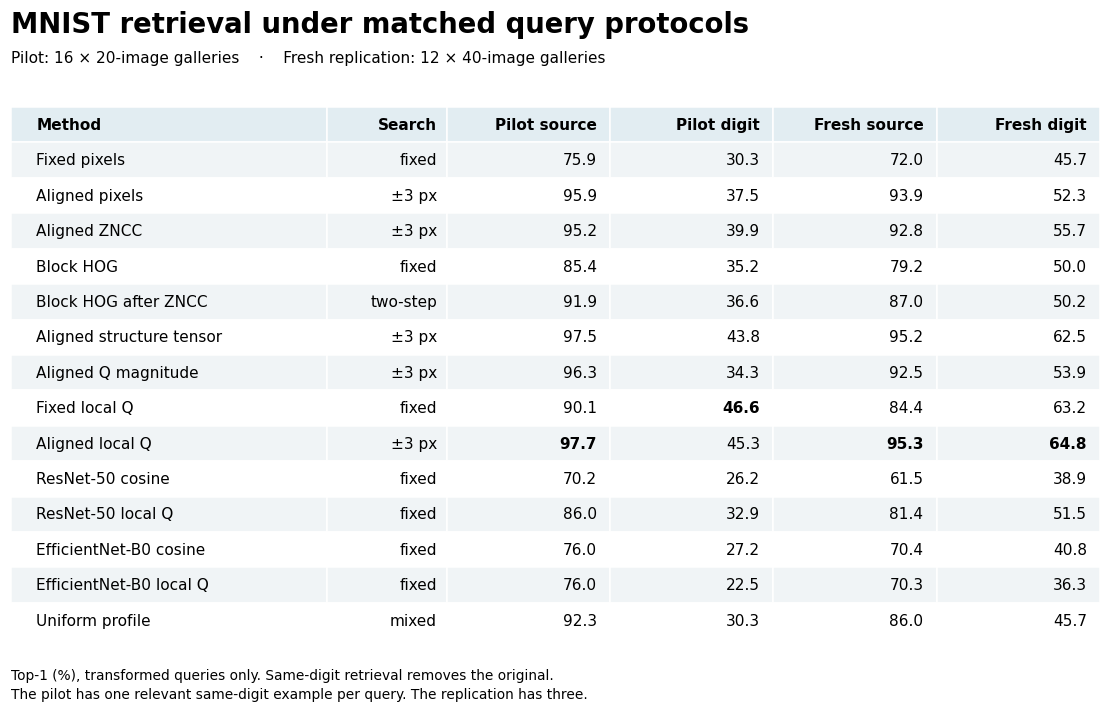

In [5]:
table=summary.query("gallery_type=='full'").pivot(index='method',columns='panel',values=['identity','class'])
chosen=[
 ('Fixed pixels','fixed','pixels'),('Aligned pixels','±3 px','aligned pixels'),
 ('Aligned ZNCC','±3 px','aligned ZNCC'),('Block HOG','fixed','standard HOG'),
 ('Block HOG after ZNCC','two-step','HOG after ZNCC'),
 ('Aligned structure tensor','±3 px','aligned structure tensor'),
 ('Aligned Q magnitude','±3 px','aligned Q magnitude'),('Fixed local Q','fixed','local Q'),
 ('Aligned local Q','±3 px','aligned local Q'),
 ('ResNet-50 cosine','fixed','ResNet-50 cosine'),('ResNet-50 local Q','fixed','ResNet-50 local Q'),
 ('EfficientNet-B0 cosine','fixed','EfficientNet-B0 cosine'),
 ('EfficientNet-B0 local Q','fixed','EfficientNet-B0 local Q'),
 ('Uniform profile','mixed','uniform profile')]
cols=[('identity','pilot'),('class','pilot'),('identity','replication'),('class','replication')]
columns=['Pilot source','Pilot digit','Fresh source','Fresh digit']
values=table.loc[[key for _,_,key in chosen],cols].to_numpy()*100
final=pd.DataFrame(values,columns=columns,index=[name for name,_,_ in chosen])
final.insert(0,'Search',[search for _,search,_ in chosen])
display(final.round(2));final.to_csv(OUT/'manuscript_comparison.csv')
fig,ax=plt.subplots(figsize=(11,6.8))
ax.set_axis_off()
fig.text(.05,.95,'MNIST retrieval under matched query protocols',weight='bold',fontsize=18)
fig.text(.05,.91,'Pilot: 16 × 20-image galleries    ·    Fresh replication: 12 × 40-image galleries',fontsize=10)
ax.set_position([.05,.14,.9,.71])
rows=[[name,search,*[f'{v:.1f}' for v in row]] for (name,search,_),row in zip(chosen,values)]
t=ax.table(cellText=rows,colLabels=['Method','Search',*columns],cellLoc='right',colLoc='right',
           colWidths=[.29,.11,.15,.15,.15,.15],bbox=[0,0,1,1])
t.auto_set_font_size(False);t.set_fontsize(10)
for (r,c),cell in t.get_celld().items():
    cell.set_edgecolor('white');cell.PAD=.08
    cell.set_facecolor('#e2edf2' if r==0 else '#f0f4f6' if r%2 else 'white')
    txt=cell.get_text()
    if c==0: txt.set_ha('left')
    if r==0 or (c>=2 and values[r-1,c-2]==values[:,c-2].max()): txt.set_weight('bold')
fig.text(.05,.085,'Top-1 (%), transformed queries only. Same-digit retrieval removes the original.',fontsize=9)
fig.text(.05,.06,'The pilot has one relevant same-digit example per query. The replication has three.',fontsize=9)
show('30_mnist_comparison')

## Scope of the remaining generalization question
The replication holds out MNIST sources and changes gallery composition. It uses the same eight perturbations and the same dataset. The learned results compare two specified frozen encoders at one image size. Transfer to a second dataset and sensitivity to encoder resolution remain separate tests.